# 01 — Exploring and Preparing the Colon Histopathology Dataset

## Introduction

The aim of this notebook was to prepare the colon subset of the LC25000 dataset for binary classification of benign colon tissue and colon adenocarcinoma. Before training the models, I examined the images for duplicates and visual similarities because closely related images in different data partitions could inflate the evaluation results.

I removed exact duplicates, examined perceptual similarity, and created group-aware training, validation, and test partitions. These steps reduced the risk of image-level leakage, although patient-level or original-slide independence could not be verified.

**Outputs:** `train.csv`, `validation.csv`, and `test.csv`, saved in `/kaggle/working/splits`.

## 1. Kaggle Environment and Dataset Location

I carried out the analysis in Kaggle using the LC25000 colon images. I first checked that both class folders were available before loading the images.

To rerun the notebook, the `andrewmvd` LC25000 dataset needed to be attached at the path used below.

In [1]:
# --- Kaggle Classic setup (LC25000 colon only) ---
# Before running:
# 1) Right sidebar -> Add data -> add 'Lung and Colon Cancer Histopathological Images (LC25000)' by andrewmvd.
# 2) Right sidebar -> Settings -> Accelerator -> GPU.

import os

data_dir = "/kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets"
print("data_dir:", data_dir)
print("Exists?", os.path.exists(data_dir))
print("classes:", os.listdir(data_dir))

data_dir: /kaggle/input/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images/lung_colon_image_set/colon_image_sets
Exists? True
classes: ['colon_aca', 'colon_n']


## 2. Importing Images and Class Labels

I created a table of image paths and labels for the two colon classes, renaming `colon_aca` and `colon_n` to `adenocarcinoma` and `benign` for clarity. This produced **10,000 images** before duplicate removal.

The original file-loading code used `os.listdir()` without sorting. I preserved this order-dependent procedure because changing it could change the saved splits used in later training.

In [2]:
# import Libraries
import cv2

import os
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import EfficientNetB3

# import statistical tools 
sns.set_style('white', {'axes.grid': True})
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
# Importing Data
def importing_data(data_dir):
    # Files and Labels Creation
    filepaths = []
    labels = []

    # Read the folders
    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)
            
# Create DF integrating all the images 
    df_filepath = pd.Series(filepaths, name='filepaths')
    df_label = pd.Series(labels, name='labels')

    data_df = pd.concat([df_filepath, df_label], axis=1)
    
    return data_df


# rename labels
def change_label_names(data_df, column_name):
    index = {'colon_aca': 'adenocarcinoma', 'colon_n': 'benign'}

#changing column name
    data_df[column_name] = data_df[column_name].replace(index)

In [4]:
data_df = importing_data(data_dir)

change_label_names(data_df, 'labels')

data_df

,filepaths,labels
0,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
1,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
2,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
3,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
4,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
...,...,...
9995,/kaggle/input/datasets/andrewmvd/lung-and-colo...,benign
9996,/kaggle/input/datasets/andrewmvd/lung-and-colo...,benign
9997,/kaggle/input/datasets/andrewmvd/lung-and-colo...,benign
9998,/kaggle/input/datasets/andrewmvd/lung-and-colo...,benign


## 3. Identifying Exact Duplicate Files

I used **SHA-256** to find files with identical contents, since duplicates appearing in different partitions could give misleading evaluation results. The analysis found **468 duplicate groups**, containing **475 extra copies**, with no groups that mixed class labels.

In [5]:

import hashlib
from collections import defaultdict

def find_exact_duplicates(df):
    hashes = defaultdict(list)

    for filepath in df["filepaths"]:
        with open(filepath, "rb") as f:
            file_hash = hashlib.sha256(f.read()).hexdigest()

        hashes[file_hash].append(filepath)

    duplicates = {
        h: paths for h, paths in hashes.items()
        if len(paths) > 1
    }

    return duplicates

duplicates = find_exact_duplicates(data_df)

print("Duplicate groups:", len(duplicates))
print("Extra duplicate files:", sum(len(paths) - 1 for paths in duplicates.values()))


Duplicate groups: 468
Extra duplicate files: 475


In [6]:

from pathlib import Path

# Check whether duplicate groups contain different class labels
conflicting_groups = []

for file_hash, paths in duplicates.items():
    labels = {Path(path).parent.name for path in paths}

    if len(labels) > 1:
        conflicting_groups.append({
            "hash": file_hash,
            "labels": labels,
            "paths": paths
        })

print("Duplicate groups with conflicting labels:",
      len(conflicting_groups))

if conflicting_groups:
    print("\nExample conflicting group:")
    print(conflicting_groups[0])


Duplicate groups with conflicting labels: 0


### Removing Extra Copies

I kept one file from each SHA-256 group, reducing the dataset from **10,000 to 9,525 images** (**4,772 benign** and **4,753 adenocarcinoma**). The code recalculated the hashes during removal; I retained that step to preserve the original workflow.

In [7]:

import hashlib

# Generate a hash for every image
def get_file_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

# Add hashes to the DataFrame
data_df["image_hash"] = data_df["filepaths"].apply(get_file_hash)

# Keep one image per unique hash
df_cleaned = data_df.drop_duplicates(
    subset="image_hash",
    keep="first"
).copy()

# Check results
print("Original images:", len(data_df))
print("Cleaned images:", len(df_cleaned))
print("Removed duplicates:", len(data_df) - len(df_cleaned))

print("\nClass distribution:")
print(df_cleaned["labels"].value_counts())


Original images: 10000
Cleaned images: 9525
Removed duplicates: 475

Class distribution:
labels
benign            4772
adenocarcinoma    4753
Name: count, dtype: int64


## 4. Examining Images with Perceptual Hashing

Exact file hashes did not capture images that looked alike but differed in their file contents. I therefore calculated **perceptual hashes (pHash)** for the 9,525 remaining images to examine possible visual similarity.

The analysis found **29 matching pHash groups** (30 additional images sharing a hash). I did not remove these images automatically because matching pHashes did not prove they were identical.

In [8]:
%pip install -q ImageHash

Note: you may need to restart the kernel to use updated packages.


In [9]:

from PIL import Image
import imagehash

# Generate perceptual hashes for the cleaned dataset
def get_phash(filepath):
    with Image.open(filepath) as img:
        return str(imagehash.phash(img.convert("RGB")))

df_cleaned["phash"] = df_cleaned["filepaths"].apply(get_phash)

# Count images with identical perceptual hashes
phash_counts = df_cleaned["phash"].value_counts()

print("Images analyzed:", len(df_cleaned))
print("Groups with matching pHash:", (phash_counts > 1).sum())
print("Extra images sharing pHash:", (phash_counts - 1).clip(lower=0).sum())


Images analyzed: 9525
Groups with matching pHash: 29
Extra images sharing pHash: 30


### Inspecting Matching pHash Values

I displayed examples from the first five matching groups to see whether the shared hashes corresponded to visible similarities between tissue images.

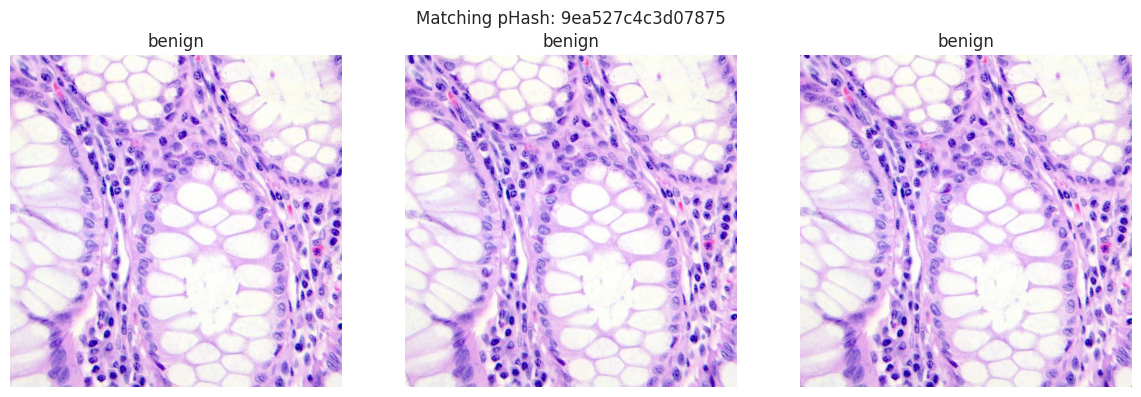

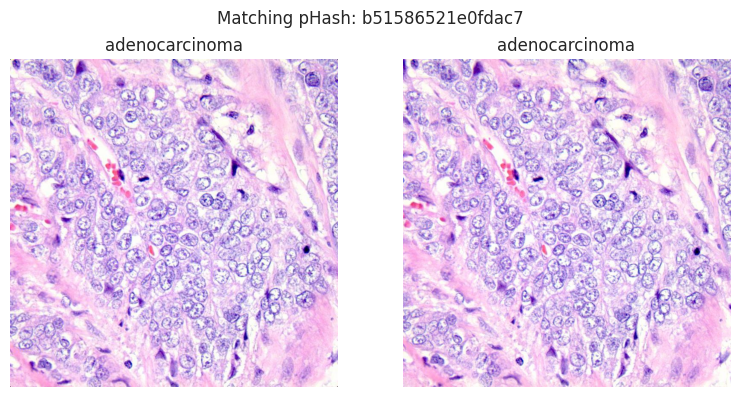

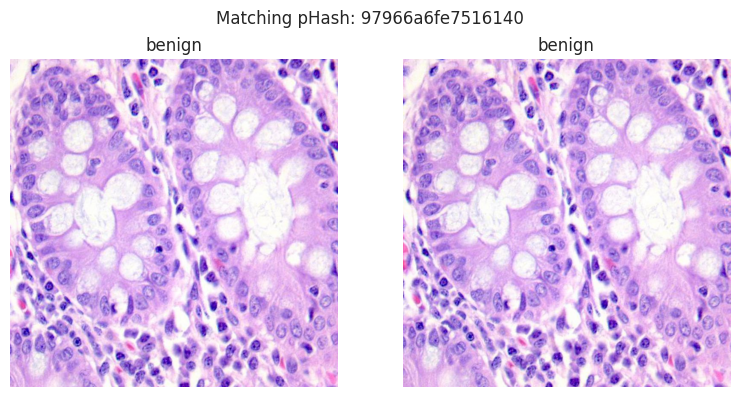

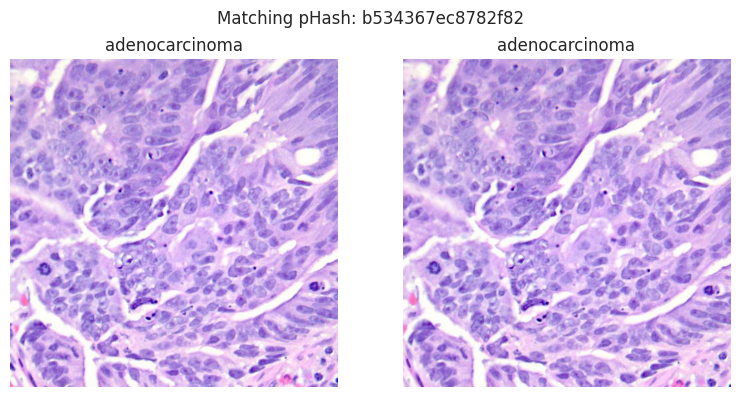

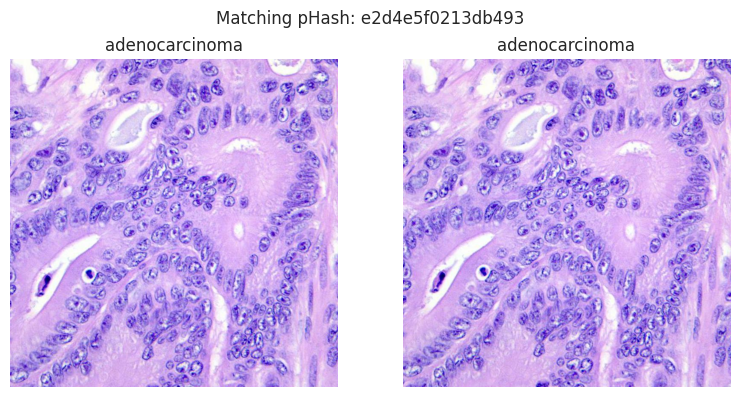

In [10]:

import matplotlib.pyplot as plt
from PIL import Image

# Find perceptual hashes shared by multiple images
matching_hashes = phash_counts[phash_counts > 1].index

# Display the first five groups
for phash_value in matching_hashes[:5]:
    matches = df_cleaned[df_cleaned["phash"] == phash_value]

    fig, axes = plt.subplots(
        1, len(matches),
        figsize=(4 * len(matches), 4),
        squeeze=False
    )

    for ax, (_, row) in zip(axes[0], matches.iterrows()):
        with Image.open(row["filepaths"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(row["labels"])
        ax.axis("off")

    plt.suptitle(f"Matching pHash: {phash_value}")
    plt.tight_layout()
    plt.show()


## 5. Searching for Nearby Perceptual Hashes

I compared pHashes using **Hamming distance**, which counts how many hash bits differ, and used a BK-tree to search efficiently. I selected a distance threshold of **five** to flag potentially related images, rather than treating it as a validated measure of duplication.

This search identified **676 pairs of distinct pHash values** within the threshold; these were hash pairs, not confirmed duplicate files.

In [11]:
%pip install -q pybktree

  Preparing metadata (setup.py) ... done
Note: you may need to restart the kernel to use updated packages.


In [12]:

import imagehash
import pybktree
from collections import defaultdict

# Convert each perceptual hash to an integer
hash_values = [
    int(h, 16) for h in df_cleaned["phash"]
]

# Hamming distance: number of differing bits
def hamming_distance(a, b):
    return (a ^ b).bit_count()

# Build a tree of unique hashes
tree = pybktree.BKTree(
    hamming_distance,
    set(hash_values)
)

# Find candidate pairs within distance 5
candidate_pairs = set()

for h in set(hash_values):
    matches = tree.find(h, 5)

    for distance, other_h in matches:
        if h != other_h:
            candidate_pairs.add(tuple(sorted((h, other_h))))

print("Nearby perceptual-hash pairs:", len(candidate_pairs))


Nearby perceptual-hash pairs: 676


### Inspecting Nearby Image Pairs

I displayed ten of the closest candidate pairs to see how their numerical similarity compared with their appearance. This was a sample check, not a visual review of every pair.

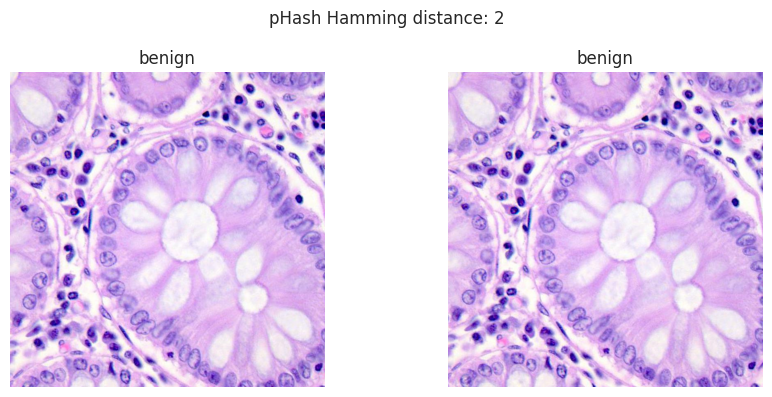

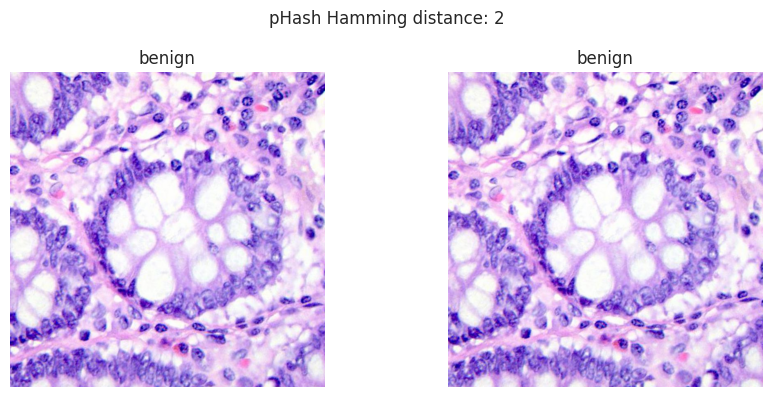

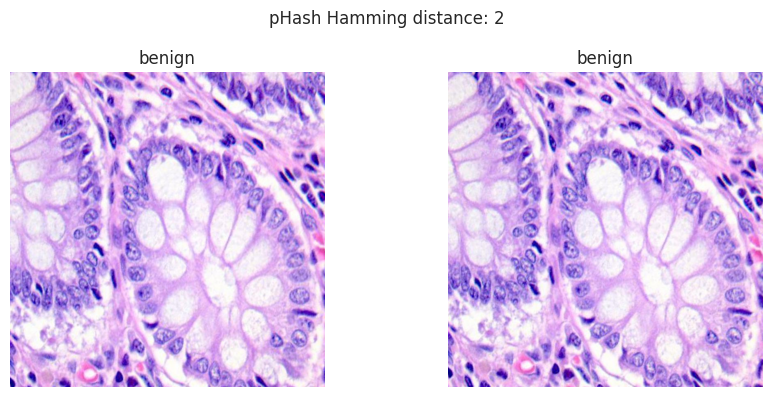

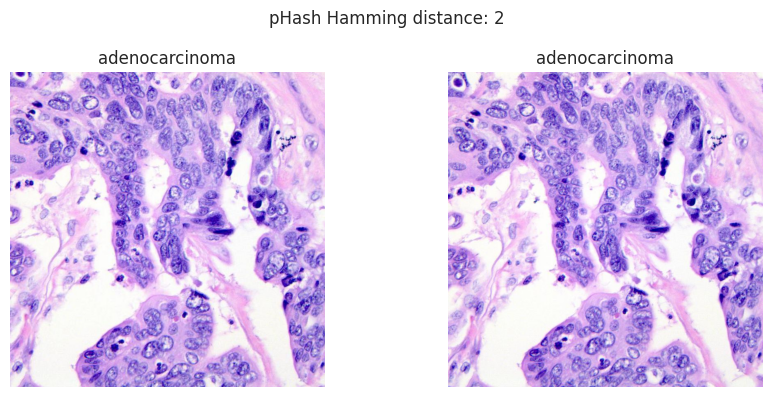

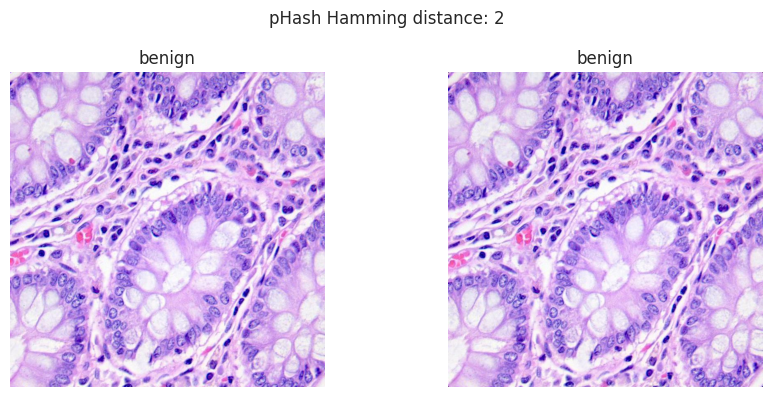

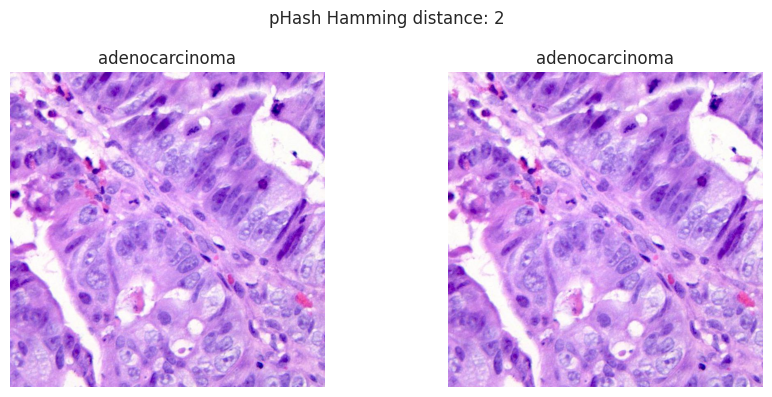

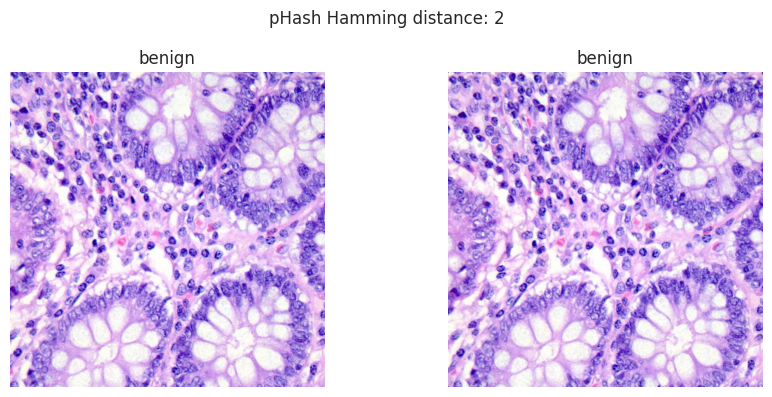

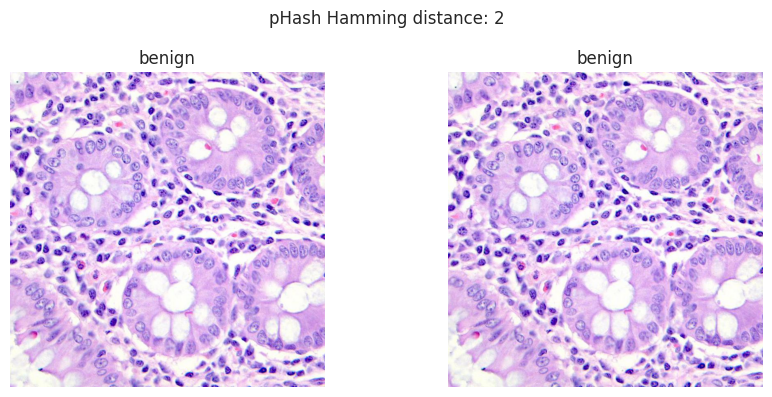

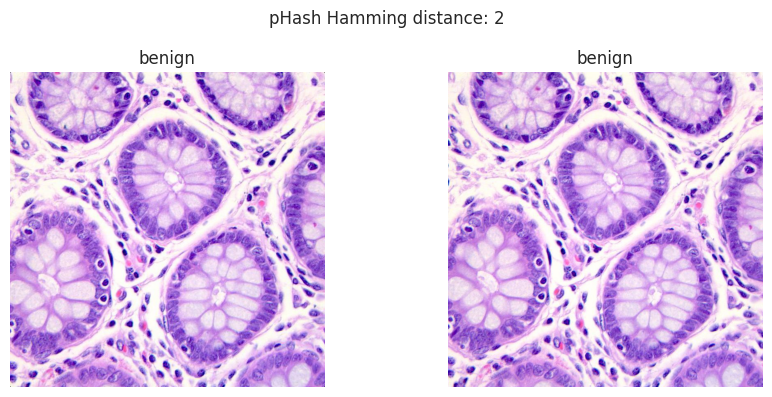

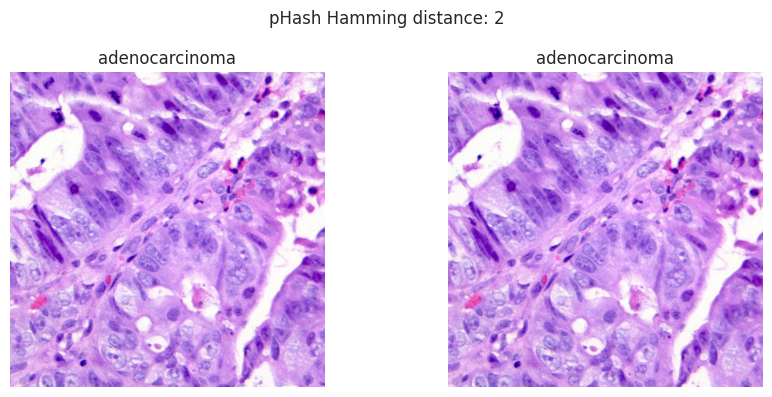

In [13]:

import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict

# Map perceptual hash values to image rows
hash_to_rows = defaultdict(list)

for idx, row in df_cleaned.iterrows():
    hash_int = int(row["phash"], 16)
    hash_to_rows[hash_int].append(row)

# Sort candidate pairs by similarity
sorted_pairs = sorted(
    candidate_pairs,
    key=lambda pair: hamming_distance(pair[0], pair[1])
)

# Display the 10 closest hash pairs
for h1, h2 in sorted_pairs[:10]:

    row1 = hash_to_rows[h1][0]
    row2 = hash_to_rows[h2][0]

    distance = hamming_distance(h1, h2)

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))

    for ax, row in zip(axes, [row1, row2]):
        with Image.open(row["filepaths"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(row["labels"])
        ax.axis("off")

    plt.suptitle(f"pHash Hamming distance: {distance}")
    plt.tight_layout()
    plt.show()


### Checking Example Filenames

I also inspected filenames from each class to check the dataset organization. The filenames did not provide evidence of patient-level or original-slide independence.

In [14]:
from pathlib import Path

print("Example filenames from each class:\n")

for label, group in df_cleaned.groupby("labels"):
    print(f"{label}:")
    for filepath in group["filepaths"].head(10):
        print(" ", Path(filepath).name)
    print()

Example filenames from each class:

adenocarcinoma:
  colonca637.jpeg
  colonca3400.jpeg
  colonca783.jpeg
  colonca3927.jpeg
  colonca4109.jpeg
  colonca95.jpeg
  colonca488.jpeg
  colonca2140.jpeg
  colonca3260.jpeg
  colonca1481.jpeg

benign:
  colonn2355.jpeg
  colonn2332.jpeg
  colonn441.jpeg
  colonn2750.jpeg
  colonn4467.jpeg
  colonn1047.jpeg
  colonn354.jpeg
  colonn4835.jpeg
  colonn3061.jpeg
  colonn4073.jpeg



## 6. Grouping Potentially Similar Images

I used **union-find** to place images linked by nearby pHashes into the same group. This allowed related images to stay together when I divided the dataset, reducing the chance of similarity-related leakage.

The analysis produced **8,826 groups**, including **638 multi-image groups** containing **1,337 images**. Because grouping was transitive, images within a group were not necessarily all within five bits of one another.

In [15]:

# Create groups of images connected by perceptual similarity

# Each unique pHash starts in its own group
hash_values = df_cleaned["phash"].apply(
    lambda h: int(h, 16)
)

unique_hashes = set(hash_values)

parent = {h: h for h in unique_hashes}

def find(h):
    if parent[h] != h:
        parent[h] = find(parent[h])
    return parent[h]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Connect nearby pHashes (Hamming distance <= 5)
for h1, h2 in candidate_pairs:
    union(h1, h2)

# Assign a group ID to each connected component
roots = sorted({find(h) for h in unique_hashes})
root_to_group = {
    root: i for i, root in enumerate(roots)
}

df_cleaned["similarity_group"] = [
    root_to_group[find(h)]
    for h in hash_values
]

# Summarize the groups
group_sizes = df_cleaned.groupby(
    "similarity_group"
).size()

print("Total images:", len(df_cleaned))
print("Similarity groups:", len(group_sizes))
print("Groups containing multiple images:",
      (group_sizes > 1).sum())
print("Images in multi-image groups:",
      group_sizes[group_sizes > 1].sum())
print("Largest group size:", group_sizes.max())


Total images: 9525
Similarity groups: 8826
Groups containing multiple images: 638
Images in multi-image groups: 1337
Largest group size: 4


### Checking Class Labels Within Groups

I checked whether any similarity group contained both classes and found **none**. This check did not independently verify that every image had the correct label.

In [16]:
print(df_cleaned[
    ["labels", "phash", "similarity_group"]
].head(10))

print("\nGroups containing both classes:")

mixed_groups = (
    df_cleaned.groupby("similarity_group")["labels"]
    .nunique()
)

print((mixed_groups > 1).sum())

           labels             phash  similarity_group
0  adenocarcinoma  fd794e0107ae198e              8729
1  adenocarcinoma  a93626c343e51eda              3080
2  adenocarcinoma  bcfa65b688e02327              4158
3  adenocarcinoma  ca8a55f2416df9a1              5251
4  adenocarcinoma  9af93266b1f40e64              2149
5  adenocarcinoma  a799ae208eb4bc6c              3004
6  adenocarcinoma  ebf469c1cf0f9808              7738
7  adenocarcinoma  c1c079de029dd9f8              4470
8  adenocarcinoma  b4d3ac5b4bac32c4              3708
9  adenocarcinoma  92e687b9e90a12f6              1415

Groups containing both classes:
0


## 7. Creating Training, Validation, and Test Splits

I used `StratifiedGroupKFold` to keep the classes relatively balanced while ensuring that images from the same similarity group stayed in one partition. I first separated a holdout fold, then split it into validation and test sets.

The final partitions contained **7,599 training**, **963 validation**, and **963 test** images, approximately an **80/10/10 split**.

In [17]:

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

# Create five approximately equal, group-aware folds
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=40
)

# Take one fold (approximately 20%) as the holdout
train_idx, holdout_idx = next(
    sgkf.split(
        df_cleaned,
        y=df_cleaned["labels"],
        groups=df_cleaned["similarity_group"]
    )
)

train_df = df_cleaned.iloc[train_idx].copy()
holdout_df = df_cleaned.iloc[holdout_idx].copy()

# Split the holdout into validation and test groups
# while approximately balancing the class proportions
sgkf_holdout = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=40
)

valid_idx, test_idx = next(
    sgkf_holdout.split(
        holdout_df,
        y=holdout_df["labels"],
        groups=holdout_df["similarity_group"]
    )
)

valid_df = holdout_df.iloc[valid_idx].copy()
test_df = holdout_df.iloc[test_idx].copy()

print("Training:", len(train_df))
print("Validation:", len(valid_df))
print("Testing:", len(test_df))


Training: 7599
Validation: 963
Testing: 963


## 8. Checking the Final Partitions

Before exporting the data, I checked that similarity groups and image paths did not overlap between partitions and that all **9,525 images** were assigned. All checks passed in the saved run.

The training set contained **3,823 benign / 3,776 adenocarcinoma** images; validation contained **469 / 494**; and test contained **480 / 483**. These checks confirmed separation under the chosen grouping method, not patient-level independence.

In [18]:

# Verify group-aware data splitting

# 1. Check for overlapping similarity groups
train_groups = set(train_df["similarity_group"])
valid_groups = set(valid_df["similarity_group"])
test_groups = set(test_df["similarity_group"])

assert train_groups.isdisjoint(valid_groups), \
    "ERROR: Training and validation groups overlap!"

assert train_groups.isdisjoint(test_groups), \
    "ERROR: Training and testing groups overlap!"

assert valid_groups.isdisjoint(test_groups), \
    "ERROR: Validation and testing groups overlap!"

# 2. Check that all images were assigned
assert (
    len(train_df) + len(valid_df) + len(test_df)
    == len(df_cleaned)
), "ERROR: Missing or duplicated images in the splits!"

# 3. Check that no image filepath appears in multiple splits
all_paths = (
    list(train_df["filepaths"])
    + list(valid_df["filepaths"])
    + list(test_df["filepaths"])
)

assert len(all_paths) == len(set(all_paths)), \
    "ERROR: Duplicate filepaths across splits!"

# 4. Display dataset sizes and class distributions
for name, df in [
    ("Training", train_df),
    ("Validation", valid_df),
    ("Testing", test_df)
]:
    print(f"\n{name}: {len(df)} images")
    print(df["labels"].value_counts())
    print(
        "Percentage:",
        round(len(df) / len(df_cleaned) * 100, 2),
        "%"
    )

print("\nAll group-overlap and split checks passed!")



Training: 7599 images
labels
benign            3823
adenocarcinoma    3776
Name: count, dtype: int64
Percentage: 79.78 %

Validation: 963 images
labels
adenocarcinoma    494
benign            469
Name: count, dtype: int64
Percentage: 10.11 %

Testing: 963 images
labels
adenocarcinoma    483
benign            480
Name: count, dtype: int64
Percentage: 10.11 %

All group-overlap and split checks passed!


## 9. Exporting the Splits

I saved the verified training, validation, and test partitions as CSV files for Notebook 02. Preserving these assignments was important because the trained models were evaluated using these particular splits; image paths may need adjustment outside Kaggle.

In [19]:

from pathlib import Path

# Create output directory
output_dir = Path("/kaggle/working/splits")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the verified dataset splits
train_df.to_csv(output_dir / "train.csv", index=False)
valid_df.to_csv(output_dir / "validation.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

print("Dataset splits saved successfully!")

for filename in ["train.csv", "validation.csv", "test.csv"]:
    print(output_dir / filename)


Dataset splits saved successfully!
/kaggle/working/splits/train.csv
/kaggle/working/splits/validation.csv
/kaggle/working/splits/test.csv


In [21]:
import os

print(os.listdir("/kaggle/working/splits"))

['test.csv', 'validation.csv', 'train.csv']


## 10. Summary and Limitations

I removed **475 exact duplicate copies** and grouped potentially similar images before creating the **80/10/10** training, validation, and test partitions. This gave the model-training notebook a more careful starting point than a simple image-level random split.

The pHash threshold was a heuristic, so some related images may have been missed or unrelated images grouped together. I also could not verify patient-level or original-slide independence. Finally, because the original file order was not explicitly sorted, rerunning the splitting procedure could produce different assignments; the saved CSVs should be reused when comparing results from the trained models.